In [1]:
import yfinance as yf
import pandas as pd
import numpy as np

In [2]:
tickers = ['SPY']
data = pd.DataFrame(yf.download(tickers, start ='2021-01-01', end = '2022-01-01')['Close'])


/tmp/ipython-input-2777834559.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = pd.DataFrame(yf.download(tickers, start ='2021-01-01', end = '2022-01-01')['Close'])
[*********************100%***********************]  1 of 1 completed


In [3]:
ret_check = data.pct_change()
ret_check['port'] = ret_check.mean(axis = 1, skipna = True)
threshold = ret_check['port'].quantile(0.04)
threshold

np.float64(-0.013490424859661121)

In [4]:
tickers = ['SPY']
df = pd.DataFrame(yf.download(tickers, start ='2022-01-01', end = '2025-08-01')['Close'])


/tmp/ipython-input-485828029.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = pd.DataFrame(yf.download(tickers, start ='2022-01-01', end = '2025-08-01')['Close'])
[*********************100%***********************]  1 of 1 completed


In [5]:
ret = df.pct_change()
ret['port'] = ret.mean(axis = 1, skipna = True)


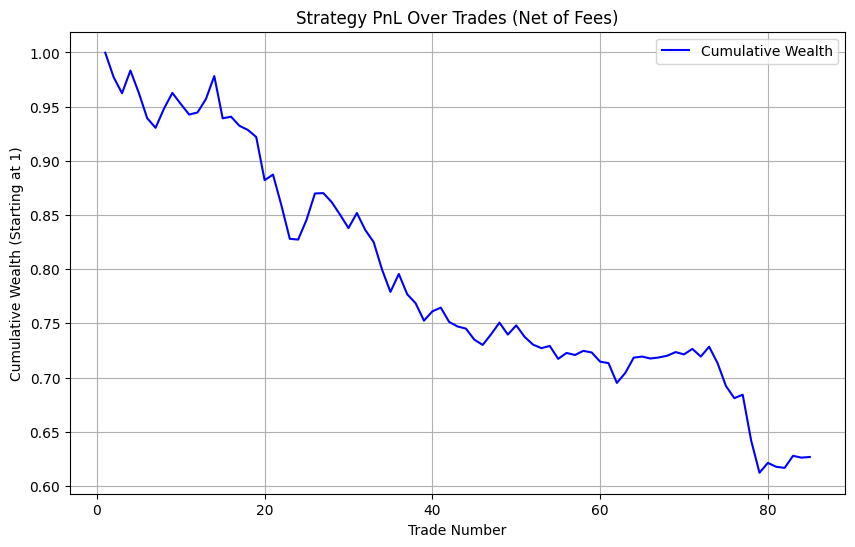

Holding Period: 5 days, Strategy Return (Net of Fees): -0.3733
Number of Trades: 85
Sharpe Ratio: -4.8987
Maximum Drawdown: 0.3876
[np.float64(-0.00030437808367977937), np.float64(-0.022571770685873682), np.float64(-0.015172388427898698), np.float64(0.02176093068005236), np.float64(-0.020911776880363497), np.float64(-0.024297401214854686), np.float64(-0.009455697388012885), np.float64(0.018997922433731107), np.float64(0.015341038191955647), np.float64(-0.010558802303725745), np.float64(-0.010286217842982781), np.float64(0.002023805286392122), np.float64(0.013094266493228313), np.float64(0.022183555705494795), np.float64(-0.03984473647307385), np.float64(0.0015703066344479044), np.float64(-0.008951157379518793), np.float64(-0.0040407966686134555), np.float64(-0.007045385730347742), np.float64(-0.043190466475251044), np.float64(0.005808418137908999), np.float64(-0.03190864879918587), np.float64(-0.0359967102605564), np.float64(-0.0008509252195291195), np.float64(0.022098266003611533), np

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def calculate_sharpe_ratio(returns: list, risk_free_rate: float = 0.0) -> float:
    """
    Calculate Sharpe ratio for a list of trade returns.
    Args:
        returns: List of trade returns.
        risk_free_rate: Risk-free rate (default 0).
    Returns:
        Sharpe ratio, or 0 if returns are empty or std is 0.
    """
    if not returns:
        return 0.0
    mean_return = np.mean(returns)
    std_return = np.std(returns, ddof=1)
    if std_return == 0:
        return 0.0
    return (mean_return - risk_free_rate) / std_return * np.sqrt(252)

def calculate_max_drawdown(returns: list) -> float:
    """
    Calculate maximum drawdown from a list of trade returns.
    Args:
        returns: List of trade returns.
    Returns:
        Maximum drawdown as a positive percentage, or 0 if no returns.
    """
    if not returns:
        return 0.0
    wealth = np.cumprod(1 + np.array(returns))  # Cumulative wealth path
    peak = np.maximum.accumulate(wealth)
    drawdowns = (peak - wealth) / peak
    return np.max(drawdowns) if len(drawdowns) > 0 else 0.0

def plot_pnl(returns: list) -> None:
    """
    Plot the cumulative PnL from a list of trade returns.
    Args:
        returns: List of trade returns.
    """
    if not returns:
        print("No trades to plot.")
        return
    # Calculate cumulative wealth path
    wealth = np.cumprod(1 + np.array(returns))
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(wealth) + 1), wealth, label='Cumulative Wealth', color='blue')
    plt.title('Strategy PnL Over Trades (Net of Fees)')
    plt.xlabel('Trade Number')
    plt.ylabel('Cumulative Wealth (Starting at 1)')
    plt.grid(True)
    plt.legend()
    plt.show()

# Original code with fee added
hold_period = 5
trade_fee = 0.003  # 0.1% fee per trade
strat_ret = []
# Iterate over DataFrame rows
for i, (index, row) in enumerate(ret.iterrows()):
    # Check if portfolio value is in the bottom 1%
    if pd.notna(row['port']) and row['port'] < threshold:
        # Ensure we don't go out of bounds
        if i + hold_period < len(ret):
            daily_ret = []
            valid = True

            ret_row = ret.iloc[i + hold_period]
            # Check for valid data
            if pd.notna([ret_row['SPY']]).all():
                # daily_ret.append(-(ret_row['SPY']/ + ret_row['GC=F'] - ret_row['BTC-USD'])/3)
                daily_ret.append(ret_row['port'])
            else:
                valid = False
                break
        if valid and daily_ret:
            # Compound daily returns for the trade
            trade_ret = np.prod(1 + np.array(daily_ret)) - 1
            # Apply transaction fee
            trade_ret = (1 + trade_ret) * (1 - trade_fee) - 1
            strat_ret.append(trade_ret)
# Compound all trade returns for the holding period
if strat_ret:  # Only compute if there are valid trade returns
    total_strat_ret = np.prod(1 + np.array(strat_ret)) - 1
else:
    total_strat_ret = 0  # No valid trades for this period

# Additional metrics
num_trades = len(strat_ret)
sharpe_ratio = calculate_sharpe_ratio(strat_ret)
max_drawdown = calculate_max_drawdown(strat_ret)

# Plot PnL
plot_pnl(strat_ret)

# Output results
print(f"Holding Period: {hold_period} days, Strategy Return (Net of Fees): {total_strat_ret:.4f}")
print(f"Number of Trades: {num_trades}")
print(f"Sharpe Ratio: {sharpe_ratio:.4f}")
print(f"Maximum Drawdown: {max_drawdown:.4f}")
print(strat_ret)